In [9]:
# Data handling
import warnings
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Modelling - split, preprocess, pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder

# Modelling - the estimators themselves
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluation
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve,ConfusionMatrixDisplay)



warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Same chart theme as the EDA notebook, so the two read as one piece of work.
plt.style.use("ggplot")
RISK, SAFE = plt.rcParams["axes.prop_cycle"].by_key()["color"][:2]   # red, blue

# One seed used everywhere, so every result in this notebook is reproducible.
SEED = 25

print("Libraries loaded.")

Libraries loaded.


In [10]:
url = "https://raw.githubusercontent.com/YBIFoundation/Dataset/main/TelecomCustomerChurn.csv"
df = pd.read_csv(url)
print(f"Raw data                 : {df.shape[0]:,} rows x {df.shape[1]} columns")

# 1. TotalCharges is text; coerce to numeric, which marks the blanks as NaN.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(f"Rows with no TotalCharges: {df['TotalCharges'].isnull().sum()} "
      f"(all Tenure == {sorted(df.loc[df['TotalCharges'].isnull(), 'Tenure'].unique())})")

# 2 & 3. Drop those rows, drop the ID column.
df = df.dropna().drop(columns="customerID").reset_index(drop=True)

print(f"Modelling data           : {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Remaining nulls          : {df.isnull().sum().sum()}")

Raw data                 : 7,043 rows x 21 columns
Rows with no TotalCharges: 11 (all Tenure == [np.int64(0)])
Modelling data           : 7,032 rows x 20 columns
Remaining nulls          : 0


In [11]:
y = (df["Churn"] == "Yes").astype(int)      # 1 = churned
X = df.drop(columns="Churn")

NUMERIC     = ["Tenure", "MonthlyCharges", "TotalCharges"]
PASSTHROUGH = ["SeniorCitizen"]                                  # already 0/1
CATEGORICAL = [c for c in X.columns if c not in NUMERIC + PASSTHROUGH]

print(f"Features : {X.shape[1]}  ({len(NUMERIC)} numeric, "
      f"{len(PASSTHROUGH)} binary, {len(CATEGORICAL)} categorical)")
print(f"Target   : churn rate = {y.mean() * 100:.2f}%  "
      f"({y.sum():,} churned / {len(y):,} customers)")
print(f"\nA 'predict nobody churns' model would score "
      f"{(1 - y.mean()) * 100:.2f}% accuracy. That is the number to keep in mind.")
print("\nCategorical columns:")
for c in CATEGORICAL:
    print(f"  {c:<18} {sorted(X[c].unique())}")

Features : 19  (3 numeric, 1 binary, 15 categorical)
Target   : churn rate = 26.58%  (1,869 churned / 7,032 customers)

A 'predict nobody churns' model would score 73.42% accuracy. That is the number to keep in mind.

Categorical columns:
  Gender             ['Female', 'Male']
  Partner            ['No', 'Yes']
  Dependents         ['No', 'Yes']
  PhoneService       ['No', 'Yes']
  MultipleLines      ['No', 'Yes']
  InternetService    ['DSL', 'Fiber optic', 'No']
  OnlineSecurity     ['No', 'Yes']
  OnlineBackup       ['No', 'Yes']
  DeviceProtection   ['No', 'Yes']
  TechSupport        ['No', 'Yes']
  StreamingTV        ['No', 'Yes']
  StreamingMovies    ['No', 'Yes']
  Contract           ['Monthly', 'One year', 'Two year']
  PaperlessBilling   ['No', 'Yes']
  PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Manual']


In [12]:
# Convert input data for model.
# .astype(int) matters: get_dummies returns bool columns, and SMOTE casts its interpolated
# values back to the input dtype - 0.3 becomes True - which corrupts the one-hot groups.
X = pd.get_dummies(X).astype(int)
X.head()

,SeniorCitizen,Tenure,MonthlyCharges,TotalCharges,Gender_Female,Gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_Yes,TechSupport_No,TechSupport_Yes,StreamingTV_No,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_Yes,Contract_Monthly,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Manual
0,0,1,29,29,1,0,0,1,1,0,1,0,1,0,1,0,0,1,0,0,1,1,0,1,0,1,0,1,0,1,0,0,0,1,0,0,1
1,0,34,56,1889,0,1,1,0,1,0,0,1,1,0,1,0,0,0,1,1,0,0,1,1,0,1,0,1,0,0,1,0,1,0,0,0,1
2,0,2,53,108,0,1,1,0,1,0,0,1,1,0,1,0,0,0,1,0,1,1,0,1,0,1,0,1,0,1,0,0,0,1,0,0,1
3,0,45,42,1840,0,1,1,0,1,0,1,0,1,0,1,0,0,0,1,1,0,0,1,0,1,1,0,1,0,0,1,0,1,0,1,0,0
4,0,2,70,151,1,0,1,0,1,0,0,1,1,0,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0,0,0,1,0,0,1


In [13]:
X.shape

(7032, 37)

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print(f"Train : {X_train.shape[0]:,} customers  |  churn rate {y_train.mean() * 100:.2f}%")
print(f"Test  : {X_test.shape[0]:,} customers  |  churn rate {y_test.mean() * 100:.2f}%")
print("\nStratification worked - the two churn rates match.")

Train : 5,625 customers  |  churn rate 26.58%
Test  : 1,407 customers  |  churn rate 26.58%

Stratification worked - the two churn rates match.


In [15]:
scaler = StandardScaler()
X_train[["MonthlyCharges","TotalCharges","Tenure"]] = scaler.fit_transform(X_train[["MonthlyCharges","TotalCharges","Tenure"]])

In [16]:
# Logistic Regression

model_lg = LogisticRegression(max_iter=5000, random_state=SEED)
model_lg.fit(X_train,y_train) # model training

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",25
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [17]:
# Random Forest Model
rf = RandomForestClassifier(random_state=SEED)
rf.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [18]:
X_test[["MonthlyCharges","TotalCharges","Tenure"]] = scaler.transform(X_test[["MonthlyCharges","TotalCharges","Tenure"]])

In [19]:
def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print(f'{model_name} Accuracy: {accuracy:.2f}')
    print(f'{model_name} Precision: {precision:.2f}')
    print(f'{model_name} Recall: {recall:.2f}')
    print(f'{model_name} F1-Score: {f1:.2f}')


    conf_matrix = confusion_matrix(y_test, y_pred)
    print(f'{model_name} Confusion Matrix:\n{conf_matrix}')

    disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=['No Churn', 'Churn'])
    disp.plot(cmap='Blues')
    plt.title(f'{model_name} Confusion Matrix')
    plt.show()


Logistic Regression Results:
Logistic Regression Accuracy: 0.80
Logistic Regression Precision: 0.66
Logistic Regression Recall: 0.56
Logistic Regression F1-Score: 0.60
Logistic Regression Confusion Matrix:
[[924 109]
 [166 208]]


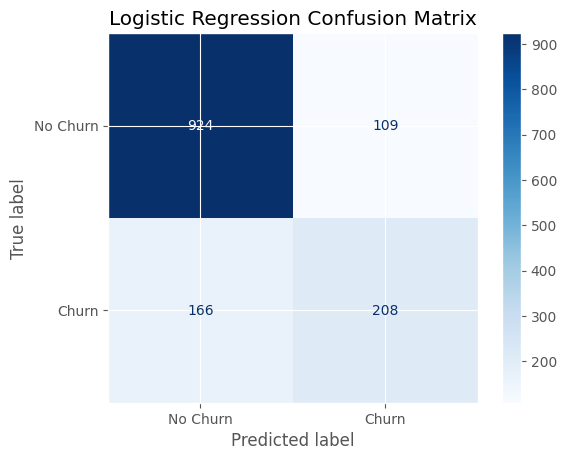

In [20]:
# Evaluate Logistic Regression model
print("\nLogistic Regression Results:")
evaluate_model(model_lg, X_test, y_test, "Logistic Regression")

Random Forest Results:
Random Forest Accuracy: 0.79
Random Forest Precision: 0.63
Random Forest Recall: 0.49
Random Forest F1-Score: 0.55
Random Forest Confusion Matrix:
[[923 110]
 [190 184]]


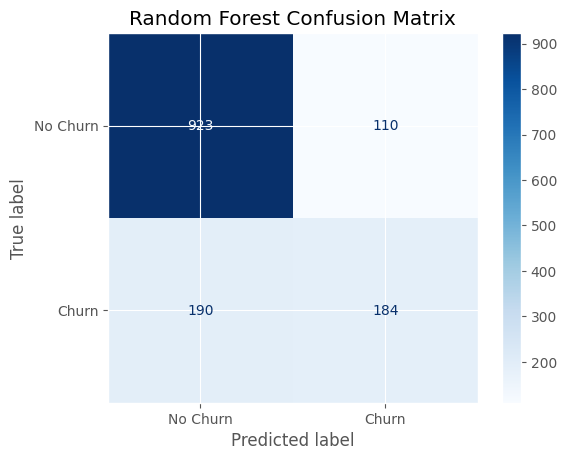

In [21]:
print("Random Forest Results:")
evaluate_model(rf, X_test, y_test, "Random Forest")

In [24]:
#from imblearn.over_sampling import SMOTE

# Split first, resample second: running SMOTE on the full dataset puts synthetic
# points built from test customers into the training set, which inflates every score.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

In [25]:
# Scale before resampling. SMOTE builds synthetic rows by interpolating between nearest
# neighbours in Euclidean space, so on raw data TotalCharges (0-8,600) swamps the 0/1
# dummies and the neighbour search effectively uses that one column.
scaler = StandardScaler()
X_train[["MonthlyCharges","TotalCharges","Tenure"]] = scaler.fit_transform(X_train[["MonthlyCharges","TotalCharges","Tenure"]])
X_test[["MonthlyCharges","TotalCharges","Tenure"]] = scaler.transform(X_test[["MonthlyCharges","TotalCharges","Tenure"]])

In [29]:
from imblearn.over_sampling import SMOTE

ModuleNotFoundError: No module named 'imblearn'

In [30]:
%pip install imbalanced-learn


   ---------------------------------------- 0/2 [sklearn-compat]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   ---------------------------------------- 2/2 [imbalanced-learn]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
# Scale before resampling. SMOTE builds synthetic rows by interpolating between nearest
# neighbours in Euclidean space, so on raw data TotalCharges (0-8,600) swamps the 0/1
# dummies and the neighbour search effectively uses that one column.
scaler = StandardScaler()
X_train[["MonthlyCharges","TotalCharges","Tenure"]] = scaler.fit_transform(X_train[["MonthlyCharges","TotalCharges","Tenure"]])
X_test[["MonthlyCharges","TotalCharges","Tenure"]] = scaler.transform(X_test[["MonthlyCharges","TotalCharges","Tenure"]])

In [33]:
model_lg = LogisticRegression(max_iter=5000, random_state=SEED)
model_lg.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",25
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [34]:
rf = RandomForestClassifier(random_state=SEED)
rf.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric


Logistic Regression Results:
Logistic Regression Accuracy: 0.80
Logistic Regression Precision: 0.66
Logistic Regression Recall: 0.56
Logistic Regression F1-Score: 0.60
Logistic Regression Confusion Matrix:
[[924 109]
 [166 208]]


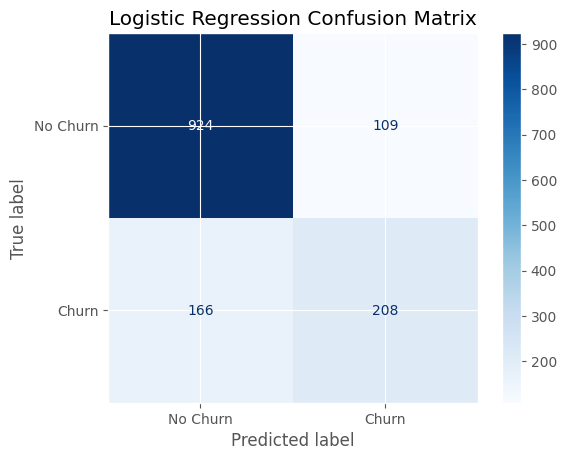

In [35]:
# Evaluate LR
print("\nLogistic Regression Results:")
evaluate_model(model_lg, X_test, y_test, "Logistic Regression")

Random Forest Results:
Random Forest Accuracy: 0.79
Random Forest Precision: 0.63
Random Forest Recall: 0.49
Random Forest F1-Score: 0.55
Random Forest Confusion Matrix:
[[923 110]
 [190 184]]


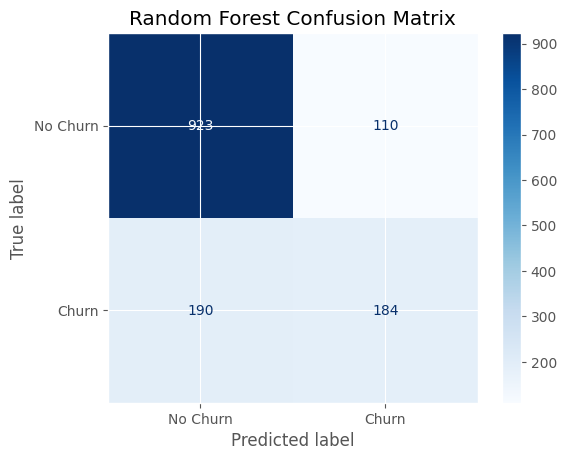

In [36]:
# Evaluate RF
print("Random Forest Results:")
evaluate_model(rf, X_test, y_test, "Random Forest")

In [37]:
# X was overwritten by get_dummies in section 4, so rebuild the raw feature frame.
X_raw = df.drop(columns="Churn")

# Split the categorical columns by how many levels they have.
BINARY = [c for c in CATEGORICAL if X_raw[c].nunique() == 2]    # -> LabelEncoder
MULTI  = [c for c in CATEGORICAL if X_raw[c].nunique() > 2]     # -> OneHotEncoder

print(f"LabelEncoder  ({len(BINARY)} two-level columns) : {BINARY}")
print(f"OneHotEncoder ({len(MULTI)} multi-level columns): {MULTI}")

LabelEncoder  (12 two-level columns) : ['Gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling']
OneHotEncoder (3 multi-level columns): ['InternetService', 'Contract', 'PaymentMethod']


In [38]:
Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    X_raw, y, test_size=0.20, stratify=y, random_state=SEED)
Xe_train, Xe_test = Xe_train.copy(), Xe_test.copy()

print(f"Train : {Xe_train.shape[0]:,} customers  |  churn rate {ye_train.mean() * 100:.2f}%")
print(f"Test  : {Xe_test.shape[0]:,} customers  |  churn rate {ye_test.mean() * 100:.2f}%")

Train : 5,625 customers  |  churn rate 26.58%
Test  : 1,407 customers  |  churn rate 26.58%


In [39]:
# 1. Two-level columns -> LabelEncoder, one per column, fitted on train only.
label_encoders = {}
for col in BINARY:
    le = LabelEncoder()
    Xe_train[col] = le.fit_transform(Xe_train[col])
    Xe_test[col]  = le.transform(Xe_test[col])
    label_encoders[col] = le                      # kept so new data can be encoded the same way

# 2. Multi-level columns -> OneHotEncoder, fitted on train only.
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=int)
ohe.fit(Xe_train[MULTI])
ohe_cols  = ohe.get_feature_names_out(MULTI)
ohe_train = pd.DataFrame(ohe.transform(Xe_train[MULTI]), columns=ohe_cols, index=Xe_train.index)
ohe_test  = pd.DataFrame(ohe.transform(Xe_test[MULTI]),  columns=ohe_cols, index=Xe_test.index)

# 3. Numeric columns -> StandardScaler, fitted on train only.
scaler_enc = StandardScaler()
num_train = pd.DataFrame(scaler_enc.fit_transform(Xe_train[NUMERIC]), columns=NUMERIC, index=Xe_train.index)
num_test  = pd.DataFrame(scaler_enc.transform(Xe_test[NUMERIC]),      columns=NUMERIC, index=Xe_test.index)

# 4. Reassemble: scaled numeric + already-binary + label-encoded + one-hot.
Xe_train = pd.concat([num_train, Xe_train[PASSTHROUGH + BINARY], ohe_train], axis=1)
Xe_test  = pd.concat([num_test,  Xe_test[PASSTHROUGH + BINARY],  ohe_test],  axis=1)

print(f"Encoded matrix: {Xe_train.shape[1]} features "
      f"({len(NUMERIC)} scaled numeric, {len(PASSTHROUGH) + len(BINARY)} label-encoded, "
      f"{len(ohe_cols)} one-hot)")
Xe_train.head()

Encoded matrix: 25 features (3 scaled numeric, 13 label-encoded, 9 one-hot)


,Tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Gender,Partner,Dependents,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Monthly,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Manual
4552,-0.956190,0.841168,-0.669928,0,1,1,1,1,1,0,0,1,0,1,0,1,0,1,0,0,1,0,0,0,1
1231,1.166017,1.104688,1.666838,1,1,1,0,1,1,0,1,1,1,1,0,1,0,1,0,0,1,0,0,0,1
6520,-1.241872,0.327387,-0.939606,1,1,0,0,1,1,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,1
5377,-0.915379,-0.635538,-0.816211,0,1,0,0,1,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,1,0
5417,0.757900,0.338989,0.711916,0,1,1,0,1,1,0,0,0,1,1,1,1,1,0,0,0,0,1,1,0,0


In [41]:
model_lg_enc = LogisticRegression(max_iter=2000, random_state=SEED)
model_lg_enc.fit(Xe_train, ye_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",25
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [42]:
rf_enc = RandomForestClassifier(random_state=SEED)
rf_enc.fit(Xe_train, ye_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

Logistic Regression Results (encoders + SMOTE):
Logistic Regression Accuracy: 0.81
Logistic Regression Precision: 0.66
Logistic Regression Recall: 0.56
Logistic Regression F1-Score: 0.60
Logistic Regression Confusion Matrix:
[[925 108]
 [166 208]]


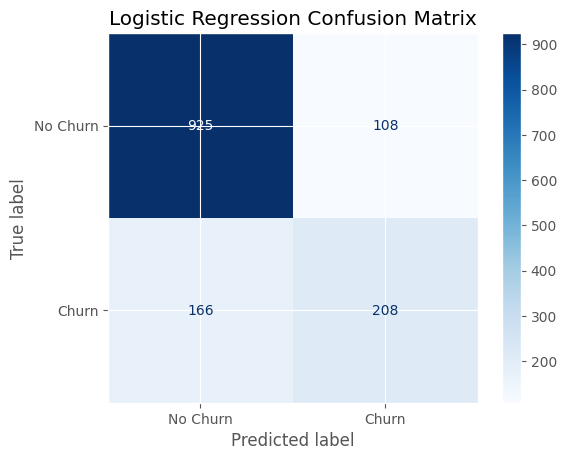

In [43]:
# Evaluate LR
print("Logistic Regression Results (encoders + SMOTE):")
evaluate_model(model_lg_enc, Xe_test, ye_test, "Logistic Regression")

Random Forest Results (encoders + SMOTE):
Random Forest Accuracy: 0.79
Random Forest Precision: 0.63
Random Forest Recall: 0.50
Random Forest F1-Score: 0.55
Random Forest Confusion Matrix:
[[922 111]
 [188 186]]


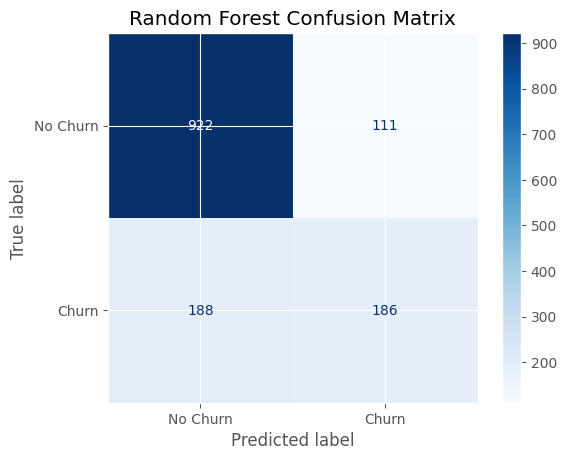

In [44]:
# Evaluate RF
print("Random Forest Results (encoders + SMOTE):")
evaluate_model(rf_enc, Xe_test, ye_test, "Random Forest")